# Cognifyz – Data Analysis Internship
## Level 2 Tasks

This notebook presents the analysis performed on the restaurant dataset for Level 2 of the Data Analysis internship.

### Tasks Covered
1. Restaurant Ratings
2. Cuisine Combination
3. Geographic Analysis
4. Restaurant Chains

## Objective

The objective of this notebook is to examine restaurant ratings, cuisine combinations, geographical distribution, and the presence of restaurant chains using data analysis and visualization techniques...

In [1]:
# Import Libraries

import pandas as pd
import matplotlib.pyplot as plt

# Display all columns
pd.set_option("display.max_columns", None)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# Upload Dataset

from google.colab import files

uploaded = files.upload()

Saving Dataset .csv to Dataset .csv


In [3]:
import os

# Display uploaded file names
print("Uploaded Files:")
print(os.listdir())

df = pd.read_csv(next(iter(uploaded)))

# Display first five rows
df.head()

Uploaded Files:
['.config', 'Dataset .csv', 'sample_data']


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## Level 2 – Task 1: Restaurant Ratings

### Objective
Analyze the distribution of restaurant ratings, identify the most common rating range, and calculate the average number of votes received by restaurants

In [4]:
# Counting restaurants across different aggregate rating categories

rating_count = df['Aggregate rating'].value_counts().sort_index()

print("Restaurant Count by Aggregate Rating\n")
print(rating_count)

Restaurant Count by Aggregate Rating

Aggregate rating
0.0    2148
1.8       1
1.9       2
2.0       7
2.1      15
2.2      27
2.3      47
2.4      87
2.5     110
2.6     191
2.7     250
2.8     315
2.9     381
3.0     468
3.1     519
3.2     522
3.3     483
3.4     498
3.5     480
3.6     458
3.7     427
3.8     400
3.9     335
4.0     266
4.1     274
4.2     221
4.3     174
4.4     144
4.5      95
4.6      78
4.7      42
4.8      25
4.9      61
Name: count, dtype: int64


In [5]:
# Creating meaningful rating categories for analysis

rating_bins = [-0.01, 0, 2, 3, 4, 5]
rating_labels = ['Not Rated', '1–2', '2–3', '3–4', '4–5']

rating_ranges = pd.cut(
    df['Aggregate rating'],
    bins=rating_bins,
    labels=rating_labels,
    include_lowest=True
)

rating_range_count = rating_ranges.value_counts().reindex(rating_labels)

print("Restaurant Distribution by Rating Range\n")
print(rating_range_count)

Restaurant Distribution by Rating Range

Aggregate rating
Not Rated    2148
1–2            10
2–3          1891
3–4          4388
4–5          1114
Name: count, dtype: int64


In [6]:
# Identifing the most common rating category

most_common_range = rating_range_count.idxmax()
most_common_count = rating_range_count.max()

print("Most Common Rating Range:\n")
print(f"{most_common_range} ({most_common_count} restaurants)")

Most Common Rating Range:

3–4 (4388 restaurants)


In [7]:
# Calculating the average number of votes received by restaurants

average_votes = df['Votes'].mean()

print("Average Number of Votes per Restaurant:\n")
print(f"{average_votes:.2f}")

Average Number of Votes per Restaurant:

156.91


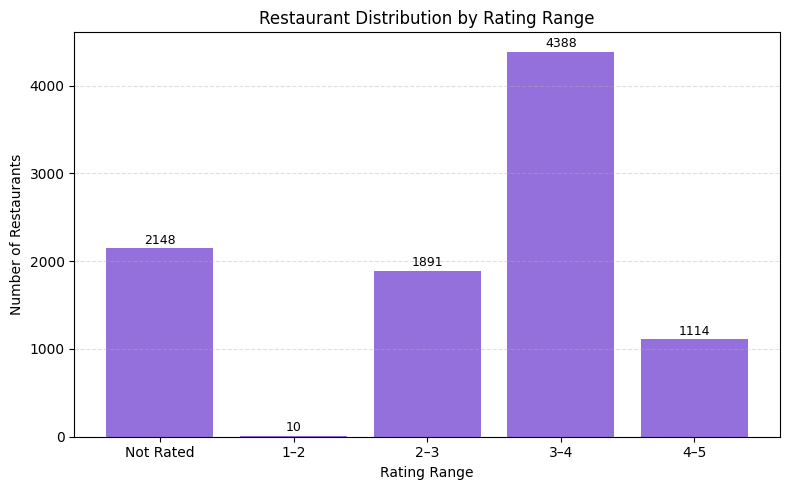

In [8]:
# Visualizing the distribution of restaurants across rating ranges

plt.figure(figsize=(8,5))

bars = plt.bar(
    rating_range_count.index,
    rating_range_count.values,
    color='mediumpurple'
)

plt.title("Restaurant Distribution by Rating Range")
plt.xlabel("Rating Range")
plt.ylabel("Number of Restaurants")

# Display restaurant counts on bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 50,
        f"{int(bar.get_height())}",
        ha='center',
        fontsize=9
    )

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

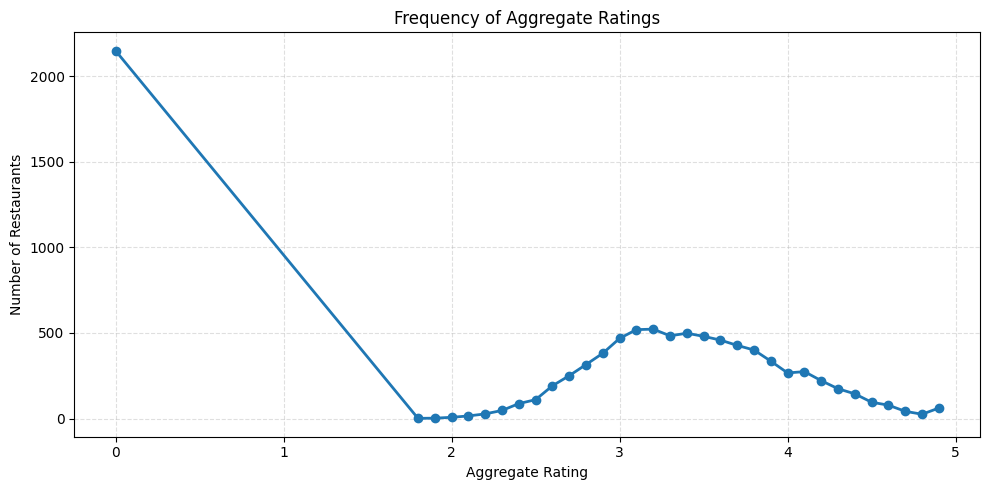

In [9]:
# Visualizing the frequency of each exact aggregate rating

plt.figure(figsize=(10,5))

rating_values = rating_count.index
rating_frequencies = rating_count.values

plt.plot(
    rating_values,
    rating_frequencies,
    marker='o',
    linewidth=2
)

plt.title("Frequency of Aggregate Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")

plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Insights

- A considerable number of restaurants are marked as "Not Rated", indicating that a rating of 0 represents the absence of a customer rating rather than a poor rating
- Among restaurants with actual ratings, the 3–4 rating range has the highest concentration of restaurants.
- Ratings above 4 are comparatively less common, showing that highly rated restaurants represent a smaller segment of the dataset
- The average number of votes is approximately 156.91 per restaurant, but the large difference between the average and median votes indicates that vote counts are highly uneven across restaurants

### Conclusion

The rating analysis shows that restaurants with ratings in the 3–4 range form the largest rated segment of the dataset. A substantial group of restaurants has no recorded rating, represented by a rating of 0. The average vote count is approximately 156.91, although voting activity varies considerably between restaurants. Overall, the dataset is concentrated around moderate-to-good ratings rather than the highest rating levels....

# Level 2 – Task 2: Cuisine Combination

### Objective
Identify the most common combinations of cuisines and examine whether frequently occurring cuisine combinations tend to have higher restaurant ratings

This analysis focuses on restaurants offering multiple cuisines together and compares their frequency and average ratings

In [10]:
# Preparing cuisine combinations for analysis

cuisine_df = df.dropna(subset=['Cuisines']).copy()

def standardize_cuisines(cuisine):
    cuisines = [item.strip() for item in cuisine.split(',')]
    cuisines = sorted(cuisines)
    return ', '.join(cuisines)

cuisine_df['Cuisine Combination'] = cuisine_df['Cuisines'].apply(
    standardize_cuisines
)

# Keep only restaurants offering more than one cuisine
multi_cuisine_df = cuisine_df[
    cuisine_df['Cuisines'].str.contains(',', regex=False)
].copy()

print("Number of restaurants with multiple cuisines:", len(multi_cuisine_df))

Number of restaurants with multiple cuisines: 6148


In [11]:
# Finding the most common cuisine combinations

cuisine_counts = (
    multi_cuisine_df['Cuisine Combination']
    .value_counts()
)

top_cuisine_combinations = cuisine_counts.head(10)

print("Top 10 Most Common Cuisine Combinations:\n")
print(top_cuisine_combinations)

Top 10 Most Common Cuisine Combinations:

Cuisine Combination
Chinese, North Indian                  616
Mughlai, North Indian                  394
Chinese, Mughlai, North Indian         306
Bakery, Desserts                       181
Chinese, Fast Food                     159
Fast Food, Pizza                       142
Chinese, North Indian, South Indian    135
Mithai, Street Food                    134
Fast Food, North Indian                120
Bakery, Fast Food                      117
Name: count, dtype: int64


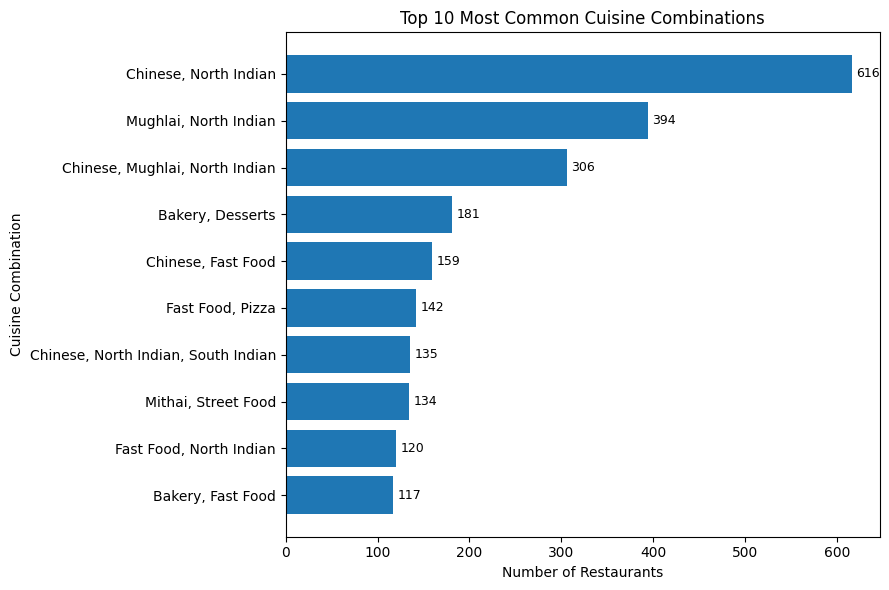

In [12]:
# Visualizing the most common cuisine combinations

plt.figure(figsize=(9, 6))

bars = plt.barh(
    top_cuisine_combinations.index[::-1],
    top_cuisine_combinations.values[::-1]
)

plt.title("Top 10 Most Common Cuisine Combinations")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine Combination")

for bar in bars:
    plt.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va='center',
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [13]:
# Comparing average ratings across cuisine combinations

cuisine_rating_stats = (
    multi_cuisine_df
    .groupby('Cuisine Combination')
    .agg(
        Restaurant_Count=('Restaurant ID', 'count'),
        Average_Rating=('Aggregate rating', 'mean')
    )
)

# Focus on combinations with enough restaurants for a meaningful comparison
reliable_combinations = (
    cuisine_rating_stats[
        cuisine_rating_stats['Restaurant_Count'] >= 20
    ]
    .sort_values('Average_Rating', ascending=False)
)

print("Highest Rated Cuisine Combinations (minimum 20 restaurants):\n")
print(reliable_combinations.head(10).round(2))

Highest Rated Cuisine Combinations (minimum 20 restaurants):

                                             Restaurant_Count  Average_Rating
Cuisine Combination                                                          
Japanese, Sushi                                            20            4.06
Italian, Pizza                                             43            3.65
Chinese, Continental, Italian, North Indian                37            3.61
Cafe, Tea                                                  21            3.41
American, Fast Food                                        22            3.39
Continental, Italian, North Indian                         32            3.34
Bakery, Desserts, Fast Food                                69            3.32
Chinese, Thai                                              54            3.32
Continental, North Indian                                  41            3.31
Burger, Fast Food                                          99            3.30


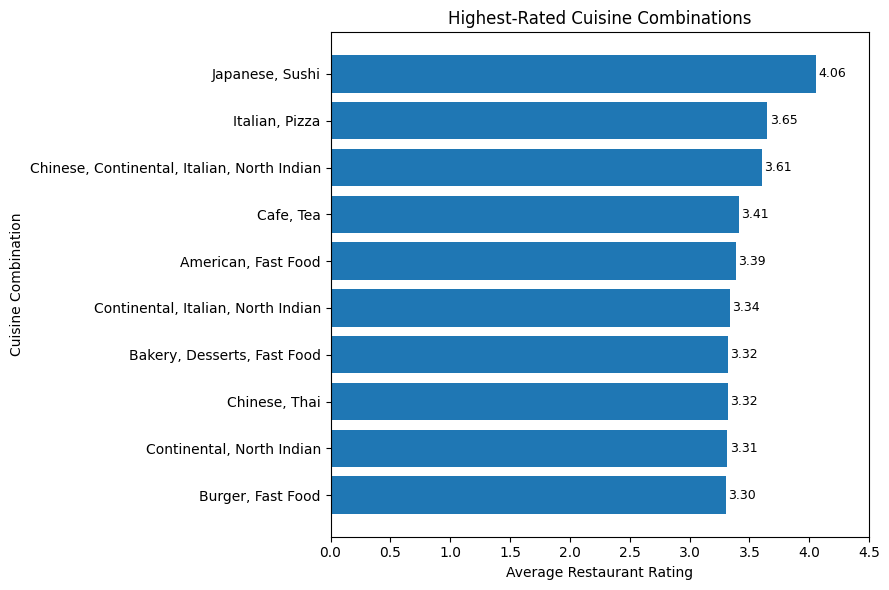

In [14]:
# Visualizing the highest-rated cuisine combinations

top_rated_combinations = reliable_combinations.head(10).sort_values(
    'Average_Rating',
    ascending=True
)

plt.figure(figsize=(9, 6))

bars = plt.barh(
    top_rated_combinations.index,
    top_rated_combinations['Average_Rating']
)

plt.title("Highest-Rated Cuisine Combinations")
plt.xlabel("Average Restaurant Rating")
plt.ylabel("Cuisine Combination")

for bar in bars:
    plt.text(
        bar.get_width() + 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va='center',
        fontsize=9
    )

plt.xlim(0, 4.5)
plt.tight_layout()
plt.show()

### Key Insights
- Japanese, Sushi had the highest average rating of 4.06 among the - combinations with at least 20 restaurants
- Italian, Pizza ranked second with an average rating of 3.65
- The remaining combinations mostly had ratings between 3.30 and 3.61, showing comparatively moderate performance
- This indicates that some specific cuisine combinations may be associated with stronger customer ratings, particularly Japanese–Sushi and Italian–Pizza

### Conclusion
The analysis shows that cuisine combinations can differ noticeably in their average restaurant ratings. Japanese, Sushi performed the best in the filtered group, while combinations such as Burger, Fast Food had relatively lower ratings. Overall, certain cuisine pairings appear to be more positively rated than others....

# Level 2 - Task 3: Geographic Analysis

### Objective
To visualize the geographical distribution of restaurants using their latitude and longitude coordinates and identify areas where restaurants are more concentrated...

In [15]:
# Select the geographic columns required for the analysis
location_df = df[['Restaurant Name', 'Latitude', 'Longitude']].dropna().copy()

print("Restaurants with valid location data:", len(location_df))
location_df.head()

Restaurants with valid location data: 9551


,Restaurant Name,Latitude,Longitude
0,Le Petit Souffle,14.565443,121.027535
1,Izakaya Kikufuji,14.553708,121.014101
2,Heat - Edsa Shangri-La,14.581404,121.056831
3,Ooma,14.585318,121.056475
4,Sambo Kojin,14.584450,121.057508


In [16]:
# Import libraries required for geographic visualization

import folium
from folium.plugins import MarkerCluster

print("Geographic visualization libraries imported successfully.")

Geographic visualization libraries imported successfully.


In [40]:
# Create an interactive map covering all restaurant locations

restaurant_map = folium.Map()

bounds = [
    [location_df['Latitude'].min(), location_df['Longitude'].min()],
    [location_df['Latitude'].max(), location_df['Longitude'].max()]
]

restaurant_map.fit_bounds(bounds)

marker_cluster = MarkerCluster().add_to(restaurant_map)

for _, row in location_df.iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=row['Restaurant Name']
    ).add_to(marker_cluster)

restaurant_map

In [41]:
# Identify cities with the highest concentration of restaurants

city_counts = (
    df['City']
    .value_counts()
)

print("Top 10 Cities by Number of Restaurants:\n")
print(city_counts.head(10))

Top 10 Cities by Number of Restaurants:

City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Ahmedabad         21
Amritsar          21
Guwahati          21
Name: count, dtype: int64


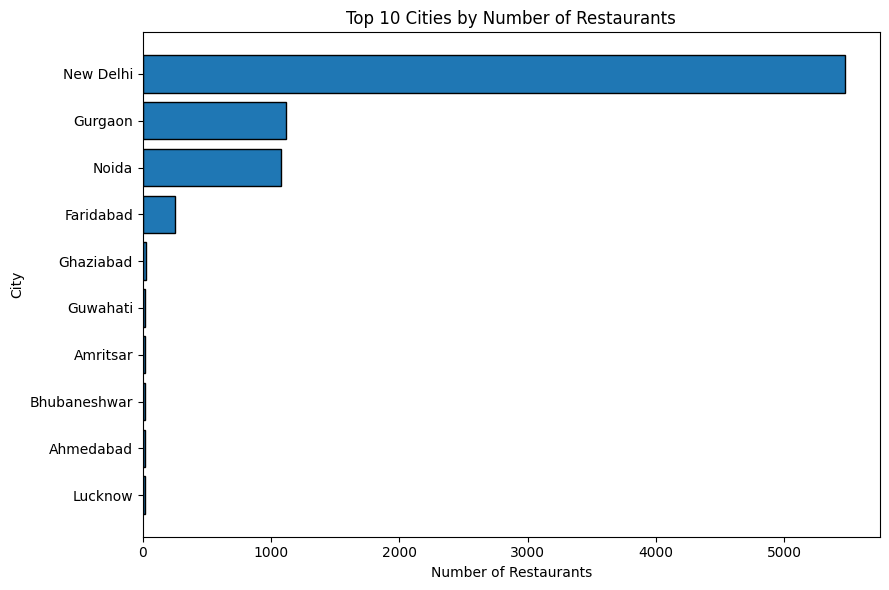

In [42]:
# Visualize the cities with the highest number of restaurants

top_cities = city_counts.head(10).sort_values(ascending=True)

plt.figure(figsize=(9, 6))

plt.barh(
    top_cities.index,
    top_cities.values,
    edgecolor='black'
)

plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")

plt.tight_layout()
plt.show()

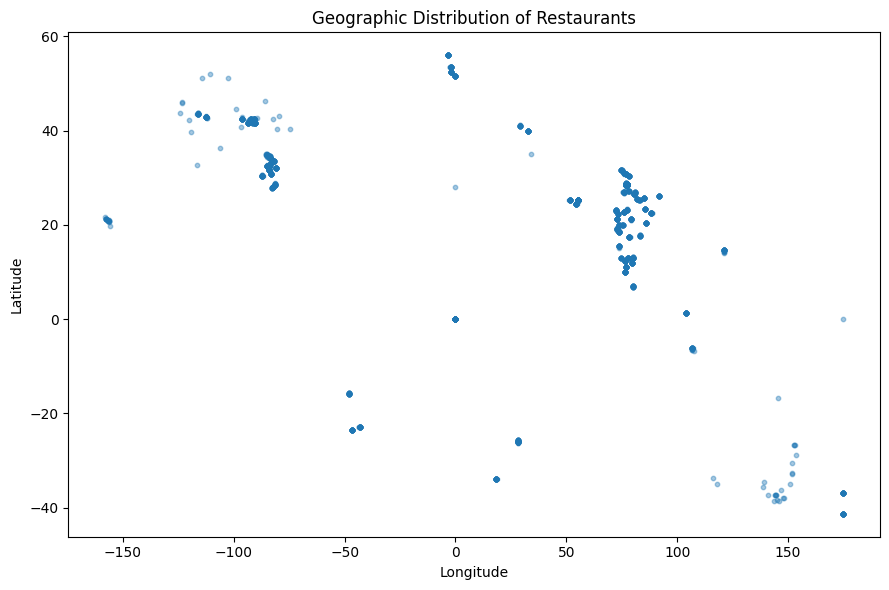

In [43]:
# Geographic Distribution

plt.figure(figsize=(9, 6))

plt.scatter(
    location_df['Longitude'],
    location_df['Latitude'],
    alpha=0.4,
    s=10
)

plt.title("Geographic Distribution of Restaurants")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

## Key Insights

- Restaurants are concentrated in a few major cities rather than being evenly distributed
- New Delhi has the highest restaurant concentration in the dataset
- The geographic map shows clear clusters of restaurants in densely represented areas

## Conclusion

The geographic analysis shows that restaurants are unevenly distributed, with strong concentrations in major cities. The location map and city-level counts help identify the areas with the highest restaurant presence...

# Level 2 - Task 4: Restaurant Chains

## Objective

To identify restaurant chains in the dataset and compare their outlet presence, ratings, and popularity based on customer votes.

In [26]:
# Identify restaurant names that appear more than once

restaurant_frequency = df['Restaurant Name'].value_counts()

restaurant_chains = restaurant_frequency[restaurant_frequency > 1]

print("Number of potential restaurant chains:", len(restaurant_chains))

print("\nTop 10 Restaurant Chains by Number of Outlets:")
print(restaurant_chains.head(10))

Number of potential restaurant chains: 734

Top 10 Restaurant Chains by Number of Outlets:
Restaurant Name
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Name: count, dtype: int64


In [27]:
# Analyze outlet count, average rating, and customer votes for restaurant chains

chain_analysis = (
    df[df['Restaurant Name'].isin(restaurant_chains.index)]
    .groupby('Restaurant Name')
    .agg(
        Outlet_Count=('Restaurant ID', 'count'),
        Average_Rating=('Aggregate rating', 'mean'),
        Total_Votes=('Votes', 'sum'),
        Average_Votes=('Votes', 'mean')
    )
    .sort_values('Outlet_Count', ascending=False)
)

print("Restaurant Chain Analysis:\n")
print(chain_analysis.head(10).round(2))

Restaurant Chain Analysis:

                  Outlet_Count  Average_Rating  Total_Votes  Average_Votes
Restaurant Name                                                           
Cafe Coffee Day             83            2.42         2428          29.25
Domino's Pizza              79            2.74         6643          84.09
Subway                      63            2.91         6124          97.21
Green Chick Chop            51            2.67          964          18.90
McDonald's                  48            3.34         5291         110.23
Keventers                   34            2.87         1263          37.15
Pizza Hut                   30            3.32         4961         165.37
Giani                       29            2.69          854          29.45
Baskin Robbins              28            1.86          428          15.29
Barbeque Nation             26            4.35        28142        1082.38


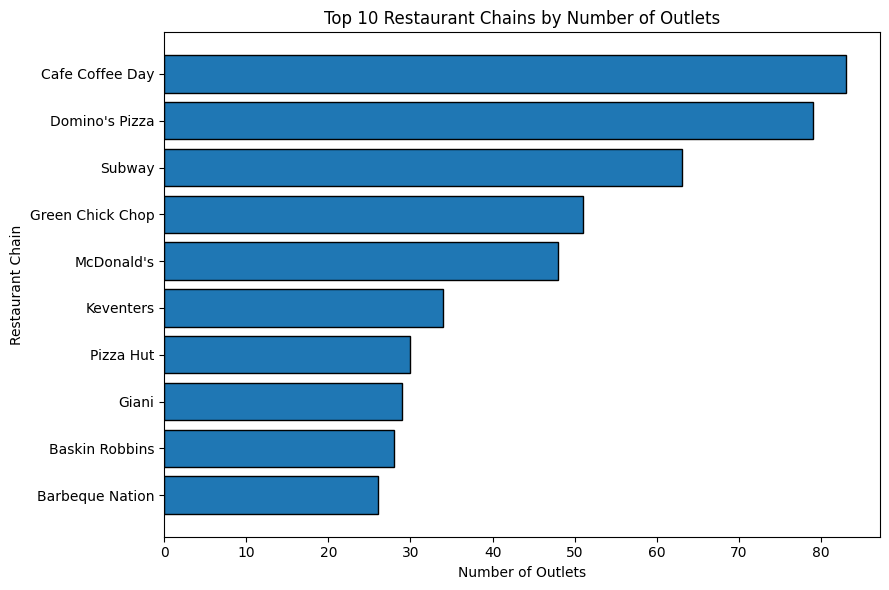

In [28]:
# Visualize the restaurant chains with the highest number of outlets

top_chains = (
    chain_analysis
    .head(10)
    .sort_values('Outlet_Count', ascending=True)
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_chains.index,
    top_chains['Outlet_Count'],
    edgecolor='black'
)

plt.title("Top 10 Restaurant Chains by Number of Outlets")
plt.xlabel("Number of Outlets")
plt.ylabel("Restaurant Chain")

plt.tight_layout()
plt.show()

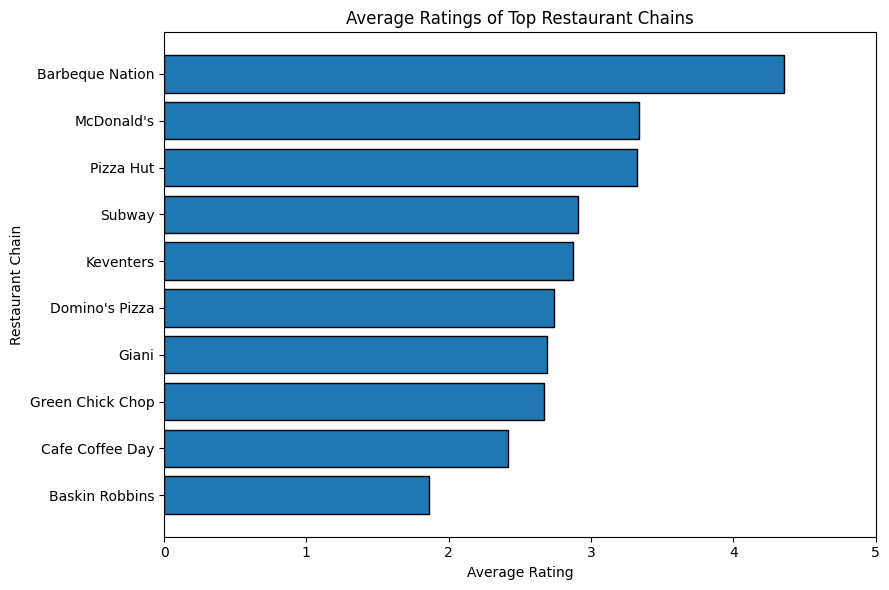

In [29]:
# Compare average ratings of the most widespread restaurant chains

rating_chains = chain_analysis.head(10).sort_values(
    'Average_Rating',
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    rating_chains.index,
    rating_chains['Average_Rating'],
    edgecolor='black'
)

plt.title("Average Ratings of Top Restaurant Chains")
plt.xlabel("Average Rating")
plt.ylabel("Restaurant Chain")

plt.xlim(0, 5)

plt.tight_layout()
plt.show()

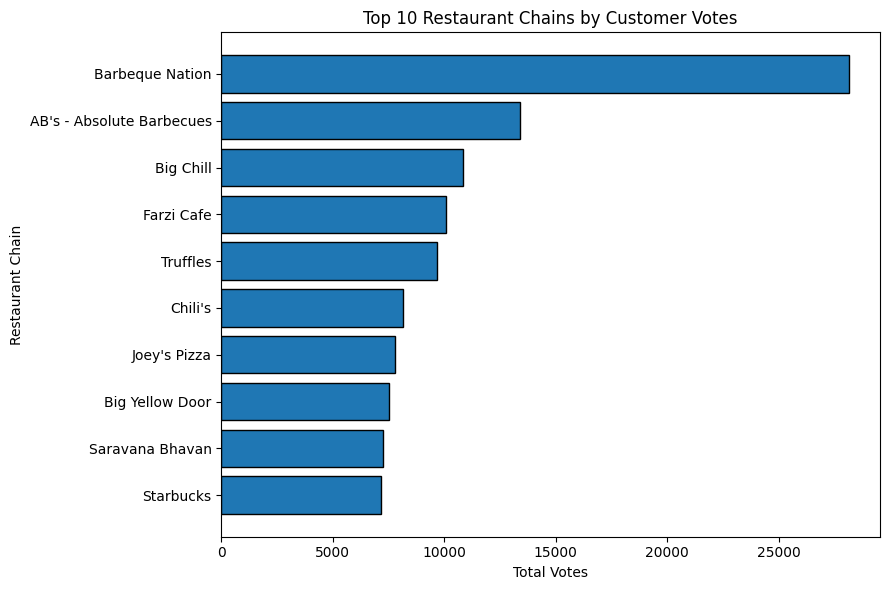

In [30]:
# Compare popularity of the top restaurant chains using total votes

popular_chains = chain_analysis.sort_values(
    'Total_Votes',
    ascending=False
).head(10)

popular_chains = popular_chains.sort_values(
    'Total_Votes',
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    popular_chains.index,
    popular_chains['Total_Votes'],
    edgecolor='black'
)

plt.title("Top 10 Restaurant Chains by Customer Votes")
plt.xlabel("Total Votes")
plt.ylabel("Restaurant Chain")

plt.tight_layout()
plt.show()

In [31]:
# Display the highest-rated restaurant chains with at least 2 outlets

highest_rated_chains = (
    chain_analysis[
        chain_analysis['Outlet_Count'] >= 2
    ]
    .sort_values('Average_Rating', ascending=False)
    .head(10)
)

print("Highest-Rated Restaurant Chains:\n")
print(highest_rated_chains.round(2))

Highest-Rated Restaurant Chains:

                           Outlet_Count  Average_Rating  Total_Votes  \
Restaurant Name                                                        
Talaga Sampireun                      3            4.90         5514   
AB's Absolute Barbecues               2            4.85         3151   
Silantro Fil-Mex                      2            4.85         1364   
AB's - Absolute Barbecues             4            4.82        13400   
Naturals Ice Cream                    2            4.80         3094   
Gymkhana                              2            4.70          328   
The Cheesecake Factory                2            4.65         3010   
Garota de Ipanema                     2            4.60           59   
Dishoom                               2            4.60         1269   
Chili's                               5            4.58         8156   

                           Average_Votes  
Restaurant Name                           
Talaga Sampireu

## Key Insights

- Several restaurant names occur across multiple outlets, indicating the presence of restaurant chains
- Chains with more outlets generally have a stronger presence across the dataset
- Customer votes provide a useful indication of chain popularity and engagement
- The highest outlet count and highest average rating do not necessarily belong to the same chain

## Conclusion

The analysis confirms the presence of multiple restaurant chains in the dataset. Comparing outlet counts, ratings, and customer votes helps distinguish chains based on their market presence, customer satisfaction, and popularity...